In [54]:
import time
import openeo
from openeo.processes import if_
import calendar
from pathlib import Path 

connection = openeo.connect(url="openeo.dataspace.copernicus.eu")
connection.authenticate_oidc()

spatial_extent_west = {"west": 610950, "east": 674650, "south": 5143820, "north": 5206380, "crs": "EPSG:32632"} # Western South Tyrol glaciers
spatial_extent_east = {"west": 704100, "east": 747040, "south": 5195880, "north": 5219660, "crs": "EPSG:32632"} # Eastern South Tyrol glaciers

output_folder = Path("/mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics")

YEARS = (2016, 2019, 2020, 2021, 2022, 2025, 2026)
MONTHS = [7,8,9]

def month_range(year, month):
    start = f"{year}-{month:02d}-01"
    ny, nm = (year + 1, 1) if month == 12 else (year, month + 1)
    return [start, f"{ny}-{nm:02d}-01"]

def monthly_products(year, month):
    cube =  connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=spatial_extent_west,
        temporal_extent=month_range(year, month),
        bands=["B02", "B03", "B04", "B08", "B11", "B12", "SCL"],
    )

    # --- cloud / shadow mask from SCL (snow = class 11 is deliberately kept) ---
    scl = cube.band("SCL")
    bad = (scl == 0) | (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)

    # --- reflectance and NDSI per scene ---
    green = cube.band("B03") * 0.0001
    nir   = cube.band("B08") * 0.0001
    swir  = cube.band("B11") * 0.0001
    ndsi  = (green - swir) / (green + swir)

    snow = ((ndsi > 0.4) & (nir > 0.11)).apply(lambda x: if_(x, 1, 0))
    snow_clear = snow.mask(bad)

    # 2) snow cover fraction = snow obs / clear obs
    snow_frac = snow_clear.reduce_dimension(dimension="t", reducer="mean")

    # 3) clear observations per pixel (and total acquisitions before masking)
    n_clear = snow_clear.reduce_dimension(dimension="t", reducer="count")
    n_total = cube.band("B03").reduce_dimension(dimension="t", reducer="count")

    # 1) visual mosaic: median of cloud-masked RGB
    cube = (
        cube.mask(bad)
        .reduce_dimension(dimension="t", reducer="median")
    )

    return cube, snow_frac, n_clear, n_total

jobs = {}
for year in YEARS:
    for month in MONTHS:
        rgb, frac, n_clear, n_total = monthly_products(year, month)
        tag = f"{year}_{month:02d}"
        for name, c in [("mosaic", rgb), ("snowfrac", frac), ("nclear", n_clear), ("ntotal", n_total)]:
            job = c.save_result(format="GTiff").create_job(title=f"{name}_{tag}")
            job.start()
            jobs[name] = job
            print(f"{name} {year} started: {job.job_id}")
            time.sleep(5)
        
    for name, job in jobs.items():
        while job.status() not in ("finished", "error", "canceled"):
            time.sleep(30)
        if job.status() == "finished":
            out_file = output_folder / f"{name}_{year}_{month}.tiff"
            job.get_results().download_file(out_file)
            print(f"Downloaded {out_file}")
        else:
            print(f"Job {name} {year} ended with status {job.status()}")

Authenticated using refresh token.
mosaic 2016 started: j-261109110023487bb04a177923fd5e54
snowfrac 2016 started: j-2611091100314bbc92cb209534c1c1cf
nclear 2016 started: j-261109110039473f909121e6cb579189
ntotal 2016 started: j-2611091100474169a30724776ffbc0f1
mosaic 2016 started: j-2611091100544ed4ad1b218ab35f7acb
snowfrac 2016 started: j-261109110102411abedbe52e0f24eec8
nclear 2016 started: j-2611091101104a5f89fdd0b44554be9b
ntotal 2016 started: j-26110911011741af9c9b1a3032576ff4
mosaic 2016 started: j-26110911012545b5a6470ac2b899e6b1
snowfrac 2016 started: j-2611091101324db98b1fe39f858fa8e9
nclear 2016 started: j-2611091101414fbab73c7603a48d8362
ntotal 2016 started: j-26110911014948c288b03bbe7b588ed2
Downloaded /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/mosaic_2016_9.tiff
Downloaded /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/snowfrac_2016_9.tiff
Downloaded /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/nclear_2016_9.ti

In [65]:
from datetime import datetime
job_create_date = datetime.strptime('2026-11-09T11:00:10Z', "%Y-%m-%dT%H:%M:%SZ")
job_list = [connection.job(j['id']) for j in connection.list_jobs() if datetime.strptime(j['created'], "%Y-%m-%dT%H:%M:%SZ") > job_create_date]
print(len(job_list), "jobs created after", job_create_date)
job_list = job_list[1:]
job_list

85 jobs created after 2026-11-09 11:00:10


[<BatchJob job_id='j-2611091329004f9faa4543c907f5f857'>,
 <BatchJob job_id='j-261109132853450c8db30367b6b9de56'>,
 <BatchJob job_id='j-26110913284647e5996a0d83921adde1'>,
 <BatchJob job_id='j-2611091328394ae0a7df676eac9c3ca3'>,
 <BatchJob job_id='j-2611091328324c9cb2efc25c62b0b57d'>,
 <BatchJob job_id='j-26110913282549f08bc3808fa4ac2503'>,
 <BatchJob job_id='j-26110913281748d8ba8c76a3f238867c'>,
 <BatchJob job_id='j-26110913280942b58f9957baeb62fab7'>,
 <BatchJob job_id='j-26110913280045b6a10490ee880dd659'>,
 <BatchJob job_id='j-2611091327524137907adafd4e447e8a'>,
 <BatchJob job_id='j-26110913274542fa8471a6b2558e23e8'>,
 <BatchJob job_id='j-26110913273744c3b272f01e2bcb846c'>,
 <BatchJob job_id='j-26110913010945fdbc8b0aea0264a166'>,
 <BatchJob job_id='j-261109130102491eb84a4f07f51f93d9'>,
 <BatchJob job_id='j-2611091300544521972505e933c9b793'>,
 <BatchJob job_id='j-2611091300474680a55af2d8266be58a'>,
 <BatchJob job_id='j-26110913004040bdbac4489df24487b7'>,
 <BatchJob job_id='j-2611091300

In [61]:
connection.list_jobs()

[{'created': '2026-11-09T13:32:10Z',
  'id': 'j-2611091332104343863c16ccc6b43e41',
  'progress': 100,
  'status': 'finished',
  'title': 'S1_mosaic',
  'updated': '2026-11-09T14:00:27Z'},
 {'created': '2026-11-09T13:29:00Z',
  'id': 'j-2611091329004f9faa4543c907f5f857',
  'progress': 100,
  'status': 'finished',
  'title': 'ntotal_2026_09',
  'updated': '2026-11-09T13:59:27Z'},
 {'created': '2026-11-09T13:28:53Z',
  'id': 'j-261109132853450c8db30367b6b9de56',
  'progress': 100,
  'status': 'finished',
  'title': 'nclear_2026_09',
  'updated': '2026-11-09T13:59:29Z'},
 {'created': '2026-11-09T13:28:46Z',
  'id': 'j-26110913284647e5996a0d83921adde1',
  'progress': 100,
  'status': 'finished',
  'title': 'snowfrac_2026_09',
  'updated': '2026-11-09T13:54:23Z'},
 {'created': '2026-11-09T13:28:39Z',
  'id': 'j-2611091328394ae0a7df676eac9c3ca3',
  'progress': 100,
  'status': 'finished',
  'title': 'mosaic_2026_09',
  'updated': '2026-11-09T13:54:25Z'},
 {'created': '2026-11-09T13:28:32Z',
  'id': 'j-2611091328324c9cb2efc25c62b0b57d',
  'progress': 100,
  'status': 'finished',
  'title': 'ntotal_2026_08',
  'updated': '2026-11-09T13:49:17Z'},
 {'created': '2026-11-09T13:28:25Z',
  'id': 'j-26110913282549f08bc3808fa4ac2503',
  'progress': 100,
  'status': 'finished',
  'title': 'nclear_2026_08',
  'updated': '2026-11-09T13:49:19Z'},
 {'created': '2026-11-09T13:28:17Z',
  'id': 'j-26110913281748d8ba8c76a3f238867c',
  'progress': 100,
  'status': 'finished',
  'title': 'snowfrac_2026_08',
  'updated': '2026-11-09T13:44:27Z'},
 {'created': '2026-11-09T13:28:09Z',
  'id': 'j-26110913280942b58f9957baeb62fab7',
  'progress': 100,
  'status': 'finished',
  'title': 'mosaic_2026_08',
  'updated': '2026-11-09T13:44:28Z'},
 {'created': '2026-11-09T13:28:00Z',
  'id': 'j-26110913280045b6a10490ee880dd659',
  'progress': 100,
  'status': 'finished',
  'title': 'ntotal_2026_07',
  'updated': '2026-11-09T13:37:27Z'},
 {'created': '2026-11-09T13:27:52Z',
  'id': 'j-2611091327524137907adafd4e447e8a',
  'progress': 100,
  'status': 'finished',
  'title': 'nclear_2026_07',
  'updated': '2026-11-09T13:37:29Z'},
 {'created': '2026-11-09T13:27:45Z',
  'id': 'j-26110913274542fa8471a6b2558e23e8',
  'progress': 100,
  'status': 'finished',
  'title': 'snowfrac_2026_07',
  'updated': '2026-11-09T13:32:22Z'},
 {'created': '2026-11-09T13:27:37Z',
  'id': 'j-26110913273744c3b272f01e2bcb846c',
  'progress': 100,
  'status': 'finished',
  'title': 'mosaic_2026_07',
  'updated': '2026-11-09T13:33:19Z'},
 {'created': '2026-11-09T13:01:09Z',
  'id': 'j-26110913010945fdbc8b0aea0264a166',
  'progress': 100,
  'status': 'finished',
  'title': 'ntotal_2025_09',
  'updated': '2026-11-09T13:27:19Z'},
 {'created': '2026-11-09T13:01:02Z',
  'id': 'j-261109130102491eb84a4f07f51f93d9',
  'progress': 100,
  'status': 'finished',
  'title': 'nclear_2025_09',
  'updated': '2026-11-09T13:27:21Z'},
 {'created': '2026-11-09T13:00:54Z',
  'id': 'j-2611091300544521972505e933c9b793',
  'progress': 100,
  'status': 'finished',
  'title': 'snowfrac_2025_09',
  'updated': '2026-11-09T13:23:18Z'},
 {'created': '2026-11-09T13:00:47Z',
  'id': 'j-2611091300474680a55af2d8266be58a',
  'progress': 100,
  'status': 'finished',
  'title': 'mosaic_2025_09',
  'updated': '2026-11-09T13:23:20Z'},
 {'created': '2026-11-09T13:00:40Z',
  'id': 'j-26110913004040bdbac4489df24487b7',
  'progress': 100,
  'status': 'finished',
  'title': 'ntotal_2025_08',
  'updated': '2026-11-09T13:18:19Z'},
 {'created': '2026-11-09T13:00:32Z',
  'id': 'j-2611091300324f9db963c4f3c20f87ab',
  'progress': 100,
  'status': 'finished',
  'title': 'nclear_2025_08',
  'updated': '2026-11-09T13:18:21Z'},
 {'created': '2026-11-09T13:00:25Z',
  'id': 'j-2611091300254428879c96669ce4c957',
  'progress': 100,
  'status': 'finished',
  'title': 'snowfrac_2025_08',
  'updated': '2026-11-09T13:14:17Z'},
 {'created': '2026-11-09T13:00:17Z',
  'id': 'j-26110913001749098053a11573c62ec6',
  'progress': 100,
  'status': 'finished',
  'title'

In [66]:
for i, j in enumerate(job_list):

    print(i, j.describe()["title"], j.status())

    if j.status() == "finished":

        title = j.describe()["title"]
        filepath = os.path.join(output_folder, f"{title}.tiff")

        print(f"Downloading: {filepath}")

        j.get_results().download_file(filepath)

        print("Done!")

0 ntotal_2026_09 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/ntotal_2026_09.tiff
Done!
1 nclear_2026_09 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/nclear_2026_09.tiff
Done!
2 snowfrac_2026_09 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/snowfrac_2026_09.tiff
Done!
3 mosaic_2026_09 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/mosaic_2026_09.tiff
Done!
4 ntotal_2026_08 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/ntotal_2026_08.tiff
Done!
5 nclear_2026_08 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/nclear_2026_08.tiff
Done!
6 snowfrac_2026_08 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO/GlacierOutlines/test_mosaics/snowfrac_2026_08.tiff
Done!
7 mosaic_2026_08 finished
Downloading: /mnt/CEPH_PROJECTS/provinzBZ_risk_EO

In [73]:
from pyproj import Transformer
from pystac_client import Client
import pandas as pd


t = Transformer.from_crs(32632, 4326, always_xy=True)
w, s_, e_, n = t.transform_bounds(
    spatial_extent_west["west"], spatial_extent_west["south"],
    spatial_extent_west["east"], spatial_extent_west["north"],
)
bbox_ll = [w, s_, e_, n]

stac = Client.open("https://stac.dataspace.copernicus.eu/v1")

rows = []
for year in range(2016, 2027):
    items = stac.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox_ll,
        datetime=f"{year}-07-01/{year}-09-30",
        max_items=None,
        limit=100,
        query={"eo:cloud_cover": {"lt": 80}},  
    ).item_collection()

    for i in items:
        rows.append({
            "year": year,
            "month": i.datetime.month,
            "date": i.datetime.date(),
            "cloud": i.properties.get("eo:cloud_cover"),
        })
    time.sleep(5)   # pause between years

raw = pd.DataFrame(rows)
df = (raw.groupby(["year", "month"])
         .agg(n_items=("date", "size"),
              n_dates=("date", "nunique"),
              mean_cloud=("cloud", "mean"))
         .reset_index())
df.to_csv(output_folder/"scene_counts.csv", index=False)

33 monthly rasters found -> snow_stats.csv


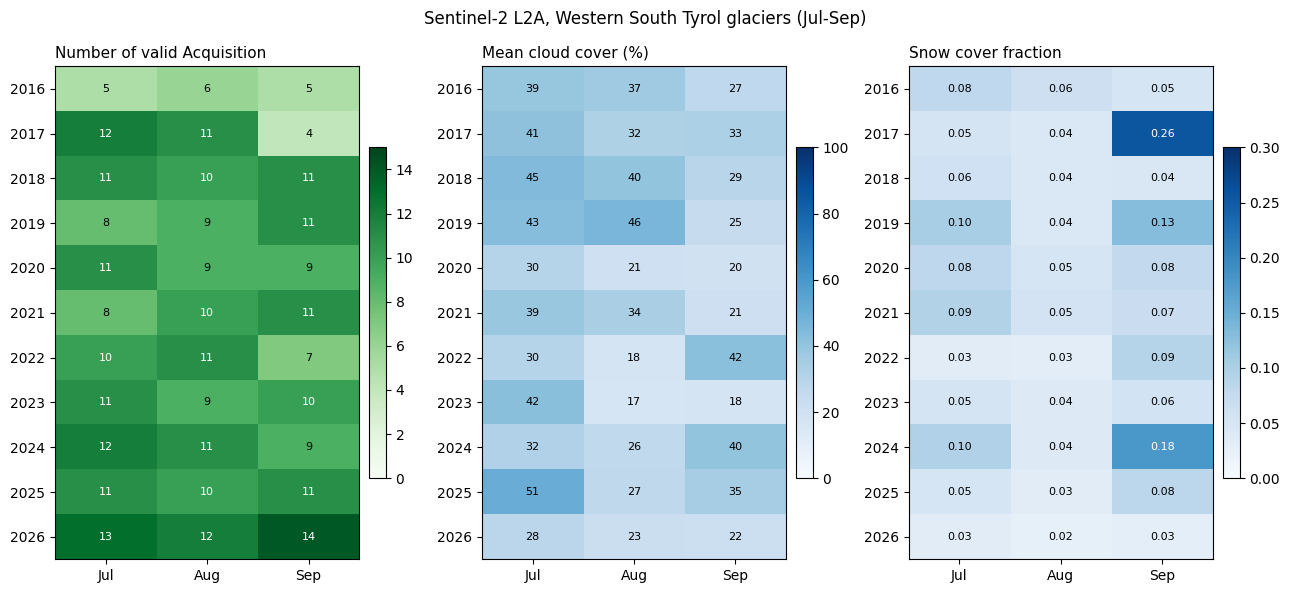

In [77]:
"""
Year x month overview: number of acquisition dates, mean cloud cover, mean snow fraction.

Inputs
  - scene_counts.csv  (columns: year, month, n_items, n_dates, mean_cloud)
  - snowfrac_YYYY_MM.tif and nclear_YYYY_MM.tif from the openEO jobs
    (band 1 = snow fraction / clear-observation count)

Install: pip install pandas numpy matplotlib rasterio
"""
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

# ------------------------------------------------------------------ settings
YEARS = range(2016, 2027)
MONTHS = [7,8,9]
LABELS = ["Jul", "Aug", "Sep"]

COUNTS_CSV = output_folder/"scene_counts.csv"

MIN_CLEAR = 2         # pixel needs at least this many clear observations
MIN_VALID = 0.3  # month is shown only if >= 30 % of the AOI has valid pixels

# ---------------------------------------------------------------------------
 
def read_masked(path):
    with rasterio.open(path) as src:
        return src.read(1, masked=True).astype("float32")
 
 
def snow_stats():
    rows = []
    for y in YEARS:
        for m in MONTHS:
            sf_file = output_folder / f"snowfrac_{y}_{m:02d}.tiff"
            nc_file = output_folder / f"nclear_{y}_{m:02d}.tiff"
            if not sf_file.exists():
                continue
            sf = read_masked(sf_file)
            valid = ~sf.mask
            if nc_file.exists():
                valid &= read_masked(nc_file).filled(0) >= MIN_CLEAR
            share = valid.mean()
            mean = sf[valid].mean() if valid.any() else np.nan
            rows.append({"year": y, "month": m, "valid_share": share,
                         "snow_frac": mean if share >= MIN_VALID else np.nan})
    df = pd.DataFrame(rows, columns=["year", "month", "valid_share", "snow_frac"])
    df.to_csv(output_folder/"snow_stats.csv", index=False)
    print(f"{len(df)} monthly rasters found -> snow_stats.csv")
    return df
 
 
def matrix(df, col):
    return df.pivot(index="year", columns="month", values=col).reindex(
        index=list(YEARS), columns=MONTHS)
 
 
def heatmap(ax, mat, title, cmap, vmax, fmt):
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("#e6e6e6")                       # grey = no data
    im = ax.imshow(np.ma.masked_invalid(mat.values.astype(float)),
                   cmap=cm, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(MONTHS)))
    ax.set_xticklabels(LABELS)
    ax.set_yticks(range(len(YEARS)))
    ax.set_yticklabels(list(YEARS))
    ax.set_title(title, fontsize=11, loc="left")
    for (i, j), v in np.ndenumerate(mat.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 * vmax else "black")
    plt.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
 
 
def main():
    counts = pd.read_csv(COUNTS_CSV)
    snow = snow_stats()
 
    fig, axes = plt.subplots(1, 3, figsize=(13, 6))
    heatmap(axes[0], matrix(counts, "n_dates"), "Number of valid Acquisition",
            "Greens", 15, "{:.0f}")
    heatmap(axes[1], matrix(counts, "mean_cloud"), "Mean cloud cover (%)",
            "Blues", 100, "{:.0f}")
    heatmap(axes[2], matrix(snow, "snow_frac"), "Snow cover fraction",
            "Blues", 0.3, "{:.2f}")
    fig.suptitle("Sentinel-2 L2A, Western South Tyrol glaciers (Jul-Sep)")
    fig.tight_layout()
    fig.savefig(output_folder/"scenes_cloud_snow_overview.png", dpi=200)
 
 
if __name__ == "__main__":
    main()
